# 04 · Evaluation
Loads the saved predictions (no retraining). Attack score = 1 − P(BENIGN). The decision threshold is picked on the **validation day** (max F1) and applied unchanged to the **test day**. Also reports recall per attack family and which *known* class each unseen attack is mapped to.

In [1]:
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
ROOT = Path('/content/drive/MyDrive/NIDS_CICIDS2017_Project')
RAW, EXTRACT, ART, PROC, REP, MODELS = [ROOT/d for d in ['raw','extracted_generated_flows','artifacts','processed','reports','models']]
for d in [RAW, EXTRACT, ART, PROC, REP, MODELS]: d.mkdir(parents=True, exist_ok=True)
SEED = 42

import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve, roc_curve,
                             precision_recall_fscore_support, confusion_matrix)
pd.set_option('display.width', 200)
KINDS = ['ftt', 'tcn', 'hybrid']; NAMES = {'ftt': 'FT-Transformer', 'tcn': 'TCN', 'hybrid': 'FT-Transformer + TCN'}
avail = [k for k in KINDS if (MODELS/k/'done.json').exists()]; print('Finished models:', avail)
known = json.loads((ART/'label_mapping.json').read_text())['known']
labels = {s: pd.read_parquet(PROC/f'{s}.parquet', columns=['Label'])['Label'].to_numpy() for s in ['val', 'test']}

R = {}
for k in avail:
    R[k] = {}
    for s in ['val', 'test']:
        p = np.load(MODELS/k/f'{s}_probs.npy'); t = np.load(MODELS/k/f'{s}_tidx.npy'); y = labels[s][t]
        R[k][s] = dict(p=p, score=1 - p[:, 0], y=y, yb=(y != 'BENIGN').astype(int))

Mounted at /content/drive
Finished models: ['ftt', 'tcn']


In [2]:
rows, THR = [], {}
for k in avail:
    v, t = R[k]['val'], R[k]['test']
    P, Rc, th = precision_recall_curve(v['yb'], v['score']); f1 = 2 * P * Rc / np.maximum(P + Rc, 1e-12)
    thr = float(th[np.argmax(f1[:-1])]); THR[k] = thr
    fpr_v, tpr_v, th_v = roc_curve(v['yb'], v['score']); thr1 = float(th_v[np.searchsorted(fpr_v, 0.01, side='right') - 1])
    row = {'model': NAMES[k], 'val_AP': average_precision_score(v['yb'], v['score']), 'val_AUC': roc_auc_score(v['yb'], v['score']), 'val_thr': thr}
    pred = (t['score'] >= thr).astype(int); pr, rc, f, _ = precision_recall_fscore_support(t['yb'], pred, average='binary', zero_division=0)
    tn, fp, fn, tp = confusion_matrix(t['yb'], pred).ravel()
    row.update({'test_AP': average_precision_score(t['yb'], t['score']), 'test_AUC': roc_auc_score(t['yb'], t['score']),
                'test_precision': pr, 'test_recall': rc, 'test_F1': f, 'test_FPR': fp / (fp + tn),
                'test_TPR@valFPR1%': ((t['score'] >= thr1) & (t['yb'] == 1)).sum() / (t['yb'] == 1).sum(),
                'test_FPR@valFPR1%': ((t['score'] >= thr1) & (t['yb'] == 0)).sum() / (t['yb'] == 0).sum()})
    rows.append(row)
res = pd.DataFrame(rows).set_index('model'); display(res.round(4)); res.to_csv(REP/'model_comparison.csv')
best = max(avail, key=lambda k: res.loc[NAMES[k], 'val_AP'])      # chosen on VALIDATION only
(ART/'best_model.json').write_text(json.dumps({'best': best, 'thresholds': THR}, indent=2)); print('Best by validation AP:', NAMES[best])

,val_AP,val_AUC,val_thr,test_AP,test_AUC,test_precision,test_recall,test_F1,test_FPR,test_TPR@valFPR1%,test_FPR@valFPR1%
model,,,,,,,,,,,
FT-Transformer,0.0322,0.9296,0.0269,0.8064,0.8895,0.7711,0.3791,0.5083,0.0785,0.2930,0.0123
TCN,0.1140,0.9564,0.0809,0.8092,0.8514,0.9751,0.3316,0.4949,0.0059,0.3401,0.0088


Best by validation AP: TCN


In [3]:
fam = {}
for s in ['val', 'test']:
    tab = {}
    for k in avail:
        r = R[k][s]; flag = r['score'] >= THR[k]
        tab[NAMES[k]] = pd.Series(flag).groupby(r['y']).mean()
    df = pd.DataFrame(tab); df.insert(0, 'n_windows', pd.Series(R[avail[0]][s]['y']).value_counts()); df['seen_in_train'] = df.index.isin(known)
    fam[s] = df; df.to_csv(REP/f'family_detection_{s}.csv')
    print(f'\n{s.upper()} - fraction flagged as attack per label (BENIGN row = false-positive rate)'); display(df.round(4))


VAL - fraction flagged as attack per label (BENIGN row = false-positive rate)


,n_windows,FT-Transformer,TCN,seen_in_train
BENIGN,456743,0.0799,0.0069,True
Infiltration,36,0.0833,0.0000,False
Web Attack - Brute Force,1507,0.9907,0.2654,False
Web Attack - Sql Injection,21,0.8571,0.0952,False
Web Attack - XSS,652,0.9831,0.2991,False



TEST - fraction flagged as attack per label (BENIGN row = false-positive rate)


,n_windows,FT-Transformer,TCN,seen_in_train
BENIGN,414313,0.0785,0.0059,True
Bot,1966,0.0010,0.0097,False
DDoS,128027,0.2281,0.7462,False
PortScan,158930,0.5055,0.0016,False


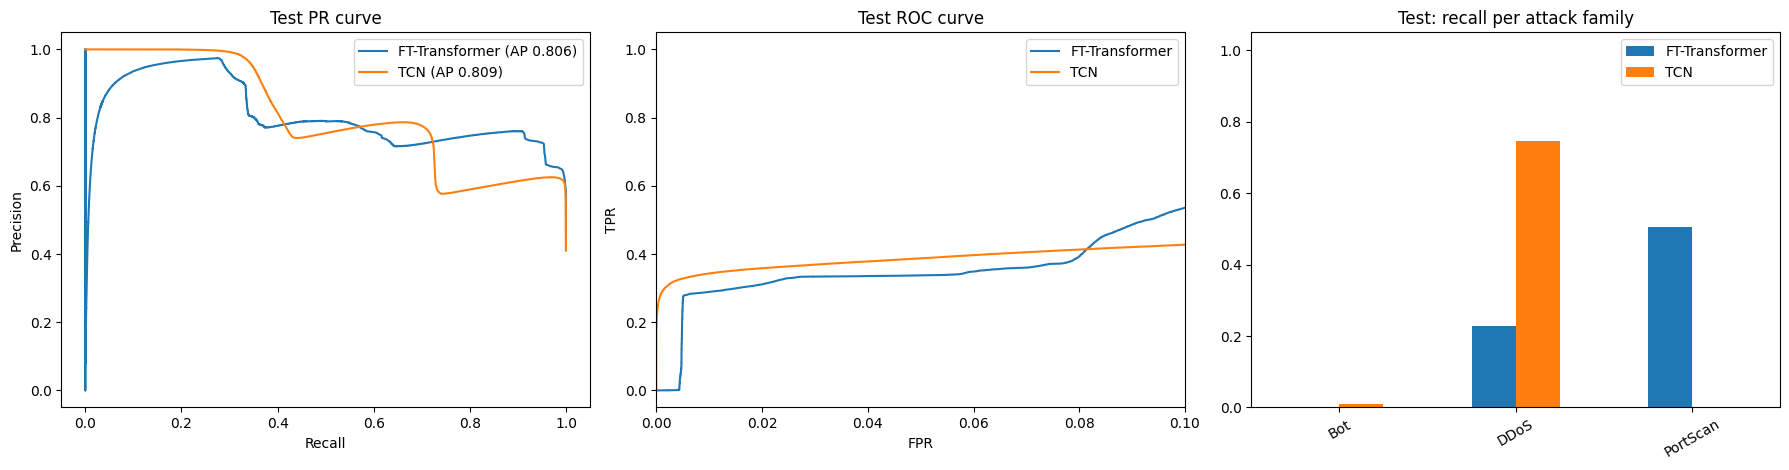

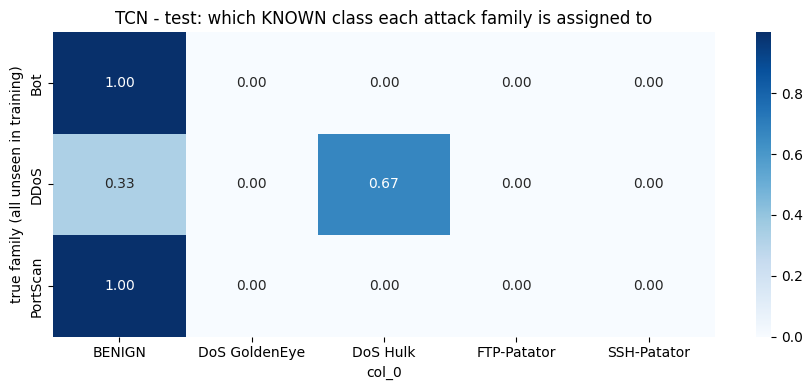

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
for k in avail:
    t = R[k]['test']; P, Rc, _ = precision_recall_curve(t['yb'], t['score']); fp_, tp_, _ = roc_curve(t['yb'], t['score'])
    ax[0].plot(Rc, P, label=f"{NAMES[k]} (AP {average_precision_score(t['yb'], t['score']):.3f})"); ax[1].plot(fp_, tp_, label=NAMES[k])
ax[0].set(title='Test PR curve', xlabel='Recall', ylabel='Precision'); ax[1].set(title='Test ROC curve', xlabel='FPR', ylabel='TPR', xlim=(0, .1))
ax[0].legend(); ax[1].legend()
d = fam['test'].drop(columns=['n_windows', 'seen_in_train']); d[d.index != 'BENIGN'].plot.bar(ax=ax[2]); ax[2].set(title='Test: recall per attack family', ylim=(0, 1.05)); ax[2].tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.savefig(REP/'eval_curves.png', dpi=150); plt.show()

r = R[best]['test']; m = r['yb'] == 1
ct = pd.crosstab(r['y'][m], np.array(known)[r['p'][m].argmax(1)], normalize='index')
plt.figure(figsize=(9, 4)); sns.heatmap(ct, annot=True, fmt='.2f', cmap='Blues'); plt.title(f'{NAMES[best]} - test: which KNOWN class each attack family is assigned to')
plt.ylabel('true family (all unseen in training)'); plt.tight_layout(); plt.savefig(REP/'attack_to_known_class.png', dpi=150); plt.show()